# IAU – Fáza 1: Prieskumná analýza dát
## Prediktívna údržba Rail APU – dataset 012
**Autori:** Tereshchenko Mykhailo, Vlad Chytnitskiy  
**Podiel práce:** Tereshchenko Mykhailo – **DOPLNIŤ %**; Vlad Chytnitskiy – **DOPLNIŤ %** (spolu 100 %).

Cieľom je preskúmať dáta, pripraviť kontrolované spojenie súborov a overiť dve hypotézy súvisiace s premennou `Failure`. Výstupom tejto fázy je audit dát, deskriptívna analýza a podklady pre predspracovanie; model sa ešte netrénuje.

In [15]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestPower
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
DATA = Path("012")
assert DATA.is_dir(), "Priečinok 012 musí byť vedľa notebooku."
raw = {"units": pd.read_csv(DATA / "units.csv", sep=","),
       "readings": pd.read_csv(DATA / "readings.csv", sep="\t"),
       "gateways": pd.read_csv(DATA / "gateways.csv", sep=";")}
sensors = [c for c in raw["readings"].columns if c not in ["unitId", "cycleTs", "Failure"]]
print("Python", platform.python_version(), "pandas", pd.__version__, "numpy", np.__version__)


Python 3.14.7 pandas 3.0.6 numpy 2.5.4


## 1.1 A – Štruktúra súborov a záznamov
`units` opisuje jednotky APU, `readings` jednotlivé merania a `gateways` komunikačné brány. Jednotka sa môže v meraniach opakovať. Brány bez `unitId` nemožno priradiť konkrétnej jednotke. Identifikátory nie sú spojité numerické prediktory. Oddeľovače sú odlišné: čiarka, tabulátor a bodkočiarka.

Počty riadkov a stĺpcov slúžia ako východisková kontrola: po čistení budeme vedieť vysvetliť každú zmenu počtu pozorovaní. Dátové typy ukážu, či sa čísla alebo dátumy omylom nenačítali ako text. Počet unikátnych hodnôt pomáha rozpoznať kľúče a kategórie. Chýbajúce hodnoty uvádzame ako počty aj percentá, pretože rovnaký počet má v rôzne veľkých tabuľkách iný význam. Ukážka troch riadkov je kontrolou formátu, nie reprezentatívnou vzorkou na závery o celej populácii.

In [16]:
overview = pd.DataFrame([{"súbor": k, "riadky": len(v), "atribúty": v.shape[1],
                           "presné duplicity": v.duplicated().sum(),
                           "chýbajúce bunky": v.isna().sum().sum()} for k,v in raw.items()])
display(overview)
for name, frame in raw.items():
    display(Markdown(f"### {name}"))
    display(frame.head(3))
    display(pd.DataFrame({"typ": frame.dtypes.astype(str), "chýba": frame.isna().sum(),
                          "chýba %": frame.isna().mean()*100, "unikátne": frame.nunique()}))


,súbor,riadky,atribúty,presné duplicity,chýbajúce bunky
0,units,2000,13,0,100
1,readings,16038,16,237,2113
2,gateways,16000,11,0,14000


### units

,year_commission,overhaul_last,codeModel,unitId,regionInstall,owner_operator,serial_number,depotId,duty_class,line_code,hours_service,code_fleet,Manufacturer
0,2022,2018-05-21,XC-7,1,Schrobenhausen,Jones-Davies,YK-9092-54795,106,3,L1,9388.9000,FD,Kabus Rogner GmbH
1,2020,07 Oct 2020,APU-15,2,Ahaus,Carvalho Leite S/A,MK-5868-13759,13,L,L6,14764.5000,FE,Köhler OHG mbH
2,2022,2017-07-05,APU-15,3,São Salvador de Lordelo,Murray Group,PI-0711-68546,62,light,L1,8476.6000,FB,Jähn AG


,typ,chýba,chýba %,unikátne
year_commission,int64,0,0.0000,13
overhaul_last,str,0,0.0000,1856
codeModel,str,0,0.0000,4
unitId,int64,0,0.0000,2000
regionInstall,str,0,0.0000,59
owner_operator,str,0,0.0000,39
serial_number,str,0,0.0000,2000
depotId,int64,0,0.0000,120
duty_class,str,0,0.0000,20
line_code,str,0,0.0000,6


### readings

,unitId,cycleTs,current_motor,dpFilter,temperature_oil,pressure_reservoir,workingPressure,oilPressure,rmsVibration,Flowmeter,humidityIntake,noise_ambient,bearing_temp,dewpointDischarge,current_aux,Failure
0,U01329,25 May 2023,6.7193,21.8777,64.7775,8.1145,7.9155,3.0207,4.6135,30.1008,65.3655,70.2995,57.6978,8.8816,3.0681,0
1,U01258,06 Sep 2023,3.1381,19.5266,34.5795,8.8247,8.6824,3.2942,1.8372,37.3440,37.7168,77.5020,65.5504,9.5817,1.2577,0
2,U01227,2023/11/03,5.8223,30.6854,61.1067,9.4746,9.4281,4.2659,2.3710,26.4613,40.1800,88.5194,71.5323,9.9230,2.1789,0


,typ,chýba,chýba %,unikátne
unitId,str,0,0.0000,2125
cycleTs,str,0,0.0000,5142
current_motor,float64,0,0.0000,15581
dpFilter,float64,609,3.7972,15162
temperature_oil,float64,0,0.0000,15693
pressure_reservoir,float64,0,0.0000,15208
workingPressure,float64,0,0.0000,15207
oilPressure,float64,0,0.0000,15220
rmsVibration,float64,677,4.2212,14891
Flowmeter,float64,0,0.0000,15679


### gateways

,Vendor,firmwareVersion,unitId,lon,macAddress,dbm_signal,lat,gatewayId,depotId,ipv4,Technician
0,Barbosa,v1.2.5,93.0000,-7.4656,3a:46:15:63:04:a8,-86.7000,38.9609,GW-00000,114,153.4.159.186,Brian Jenkins
1,Maldonado-Meadows,v3.4.1,472.0000,-7.5696,79:de:94:cf:54:f8,-80.4000,41.5532,GW-00001,19,252.36.179.106,Beth Haley
2,Kobelt Dörr e.V.,v1.2.5,1631.0000,-8.6591,9f:f5:09:dc:c2:31,-75.2000,39.9939,GW-00002,10,167.59.69.69,Reginald Ramirez


,typ,chýba,chýba %,unikátne
Vendor,str,0,0.0000,39
firmwareVersion,str,0,0.0000,3
unitId,float64,14000,87.5000,2000
lon,float64,0,0.0000,15601
macAddress,str,0,0.0000,16000
dbm_signal,float64,0,0.0000,596
lat,float64,0,0.0000,15587
gatewayId,str,0,0.0000,16000
depotId,int64,0,0.0000,120
ipv4,str,0,0.0000,16000


**Čo z auditu vyplýva:** zdroj obsahuje 2 000 jednotiek, 16 038 meraní a 16 000 brán. V meraniach sú presné duplicity; v jednotkách chýba 100 hodnôt prevádzkových hodín a väčšina brán nemá väzbu na jednotku. Rozdielny počet riadkov sám osebe nie je chyba: súbory opisujú rôzne entity. Ďalším krokom preto musí byť kontrola kľúčov a kardinality, nie jednoduché spojenie podľa poradia riadkov.

## 1.1 B – Distribúcie a charakteristiky 13 senzorov
Najprv skúmame pôvodné merania bez deduplikácie, imputácie alebo opráv. Takto vidíme aj problémy, ktoré by predčasné čistenie zakrylo. Výsledky tejto časti sú **predbežné**: duplicity a chybné hodnoty môžu skresliť štatistiky. V časti 1.2 ukážeme zmeny po čistení.

Vyberáme všetkých 13 senzorov, teda viac než požadovaných desať. Významy odvodzujeme z názvov; technické jednotky a výrobcom predpísané limity neboli dodané. Pozorované min/max preto nie sú prevádzkové limity. Nezápornosť prúdov, tlakov, prietoku a RMS a percentuálny rozsah vlhkosti sú pracovné kontroly podrobne vyhodnotené v 1.2 B.

### Prečo kombinujeme štatistiky a dva typy grafov
Priemer a smerodajná odchýlka opisujú úroveň a rozptyl, ale reagujú na extrémy. Medián a kvartily pridávajú odolnejší pohľad. Percentily 5 a 95 ukazujú stredných 90 % platných hodnôt a neskôr poskytujú hranice demonštračnej winsorizácie. Šikmosť dopĺňa vizuálny dojem z histogramu.

Histogramy zobrazujeme pre každý senzor osobitne, pretože majú rôzne rozsahy. Používame 40 intervalov ako čitateľnú vizualizačnú voľbu, nie ako odhad fyzikálnych prevádzkových režimov. Boxplot dopĺňa informáciu o chvostoch. Bod mimo jeho fúzov znamená štatistický extrém podľa IQR pravidla, nie dokázanú chybu. NaN sa pri výpočtoch vynechávajú; preto uvádzame platné počty pre každý senzor.

,význam,count,mean,std,min,5%,25%,50%,75%,95%,max,chýba %,šikmosť
current_motor,prúd motora,16038.0000,5.2659,3.4728,0.0983,2.4536,3.7172,5.0770,6.5500,8.2564,99.0000,0.0000,19.6244
dpFilter,tlakový rozdiel filtra,15429.0000,24.0185,11.3167,7.0829,11.5374,16.3434,21.3578,28.7165,45.9302,120.0000,3.7972,1.9317
temperature_oil,teplota oleja,16038.0000,51.1077,63.8566,-999.0000,34.6549,46.6856,54.8041,62.9194,74.8380,95.0000,0.0000,-15.8020
pressure_reservoir,tlak zásobníka,16038.0000,8.7086,0.6012,6.5000,7.7270,8.3007,8.7057,9.1203,9.7029,10.5000,0.0000,-0.0176
workingPressure,pracovný tlak,16038.0000,8.7067,0.6210,6.3615,7.6941,8.2844,8.7034,9.1285,9.7371,10.5000,0.0000,-0.0239
oilPressure,tlak oleja,16038.0000,3.7061,0.5686,1.5000,2.7766,3.3172,3.7088,4.0926,4.6398,5.9142,0.0000,-0.0207
rmsVibration,RMS vibrácie,15361.0000,3.0888,1.6300,0.5000,1.2031,1.9384,2.7414,3.8311,6.1586,14.0000,4.2212,1.6273
Flowmeter,prietok,16038.0000,28.0181,4.0010,15.0000,21.4429,25.3183,27.9704,30.7576,34.6273,40.0000,0.0000,0.0155
humidityIntake,vlhkosť nasávania,15211.0000,52.7148,24.5542,10.0137,14.2059,31.5687,52.5974,73.9878,90.7750,94.9976,5.1565,-0.0092
noise_ambient,okolitý hluk,16038.0000,75.0859,5.9519,55.0000,65.3159,70.9930,75.0675,79.1350,84.8922,95.0000,0.0000,-0.0115


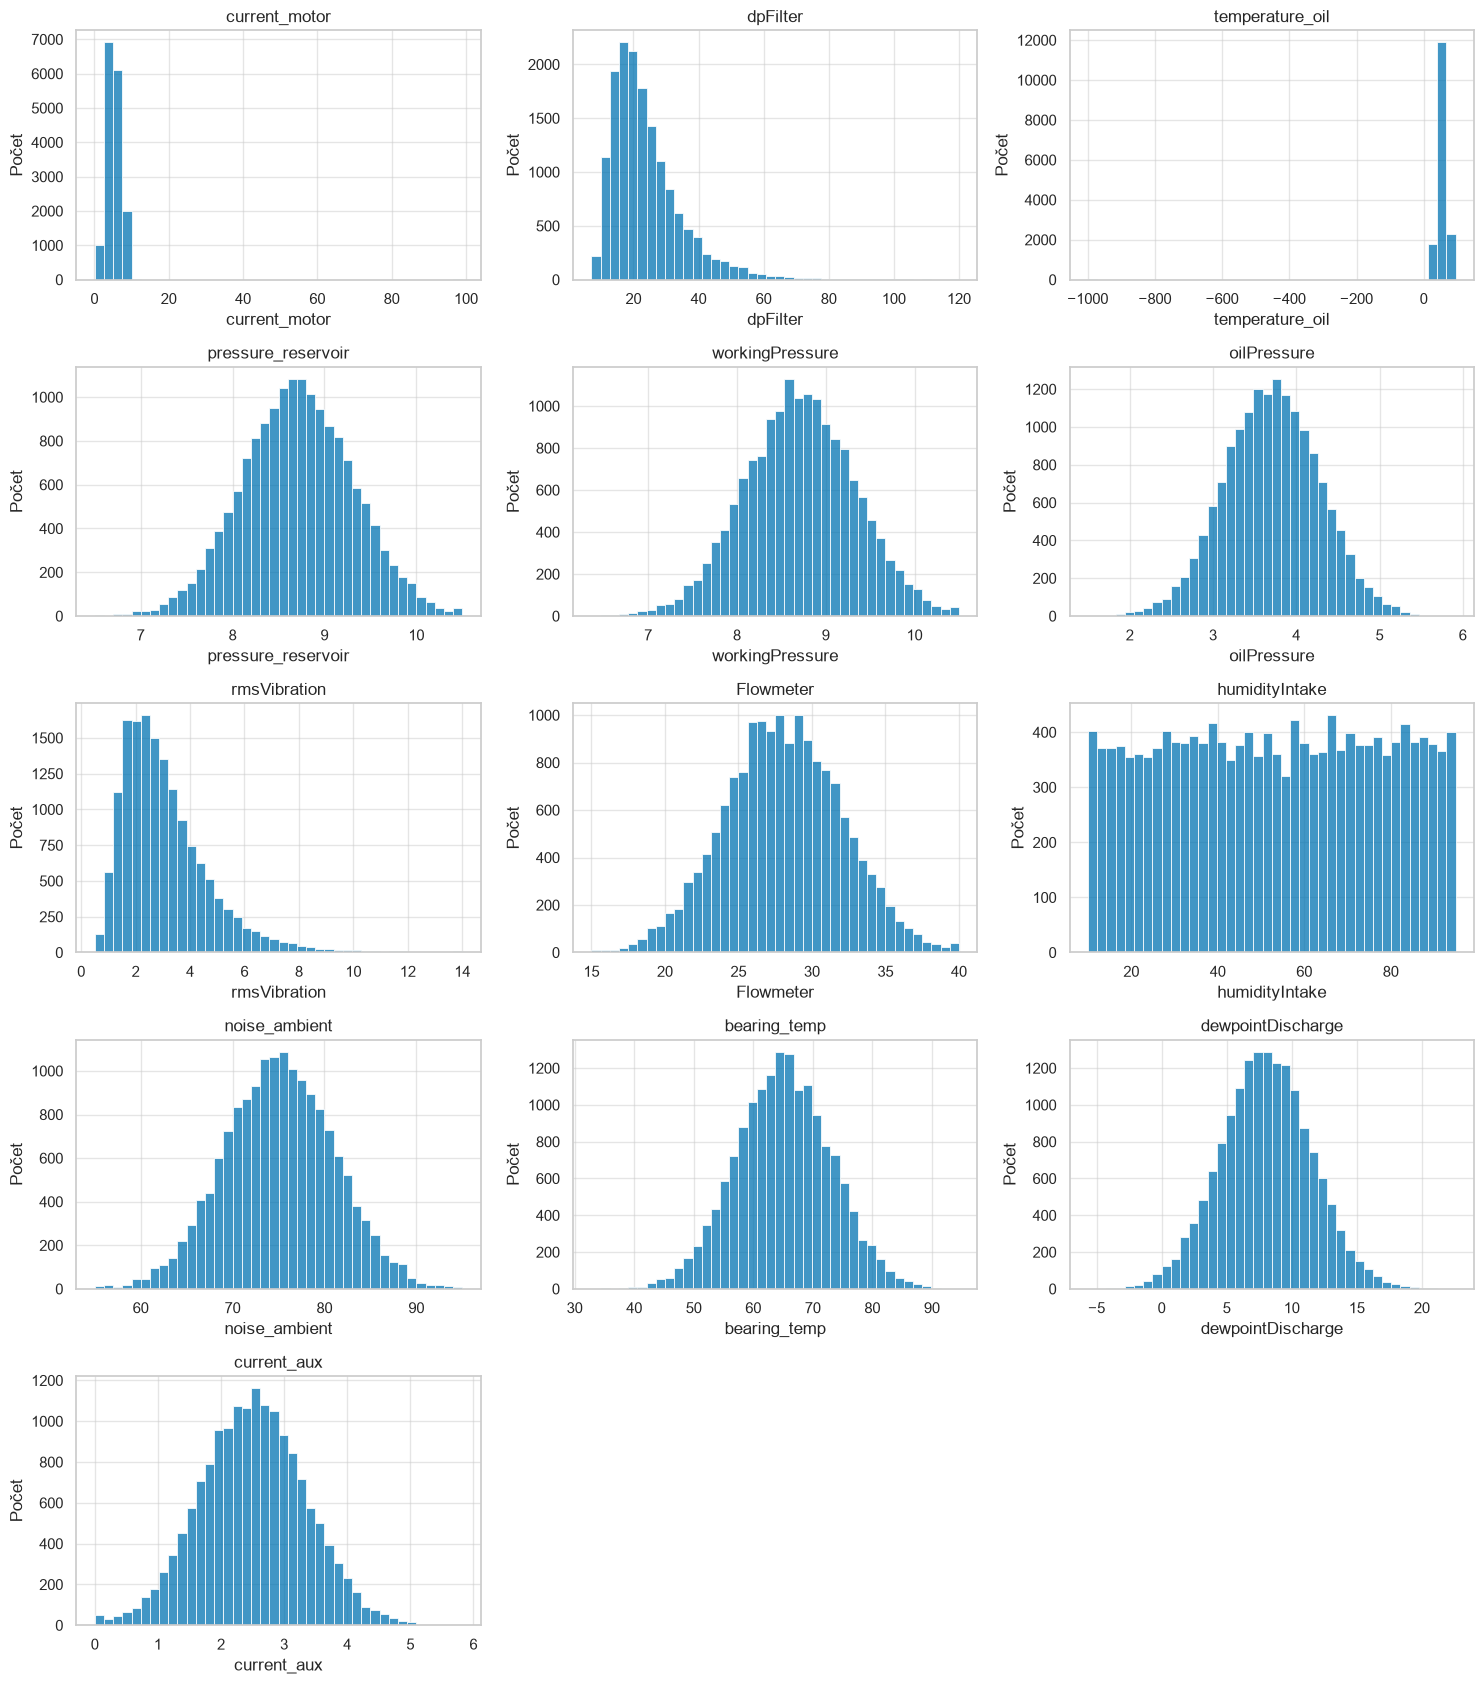

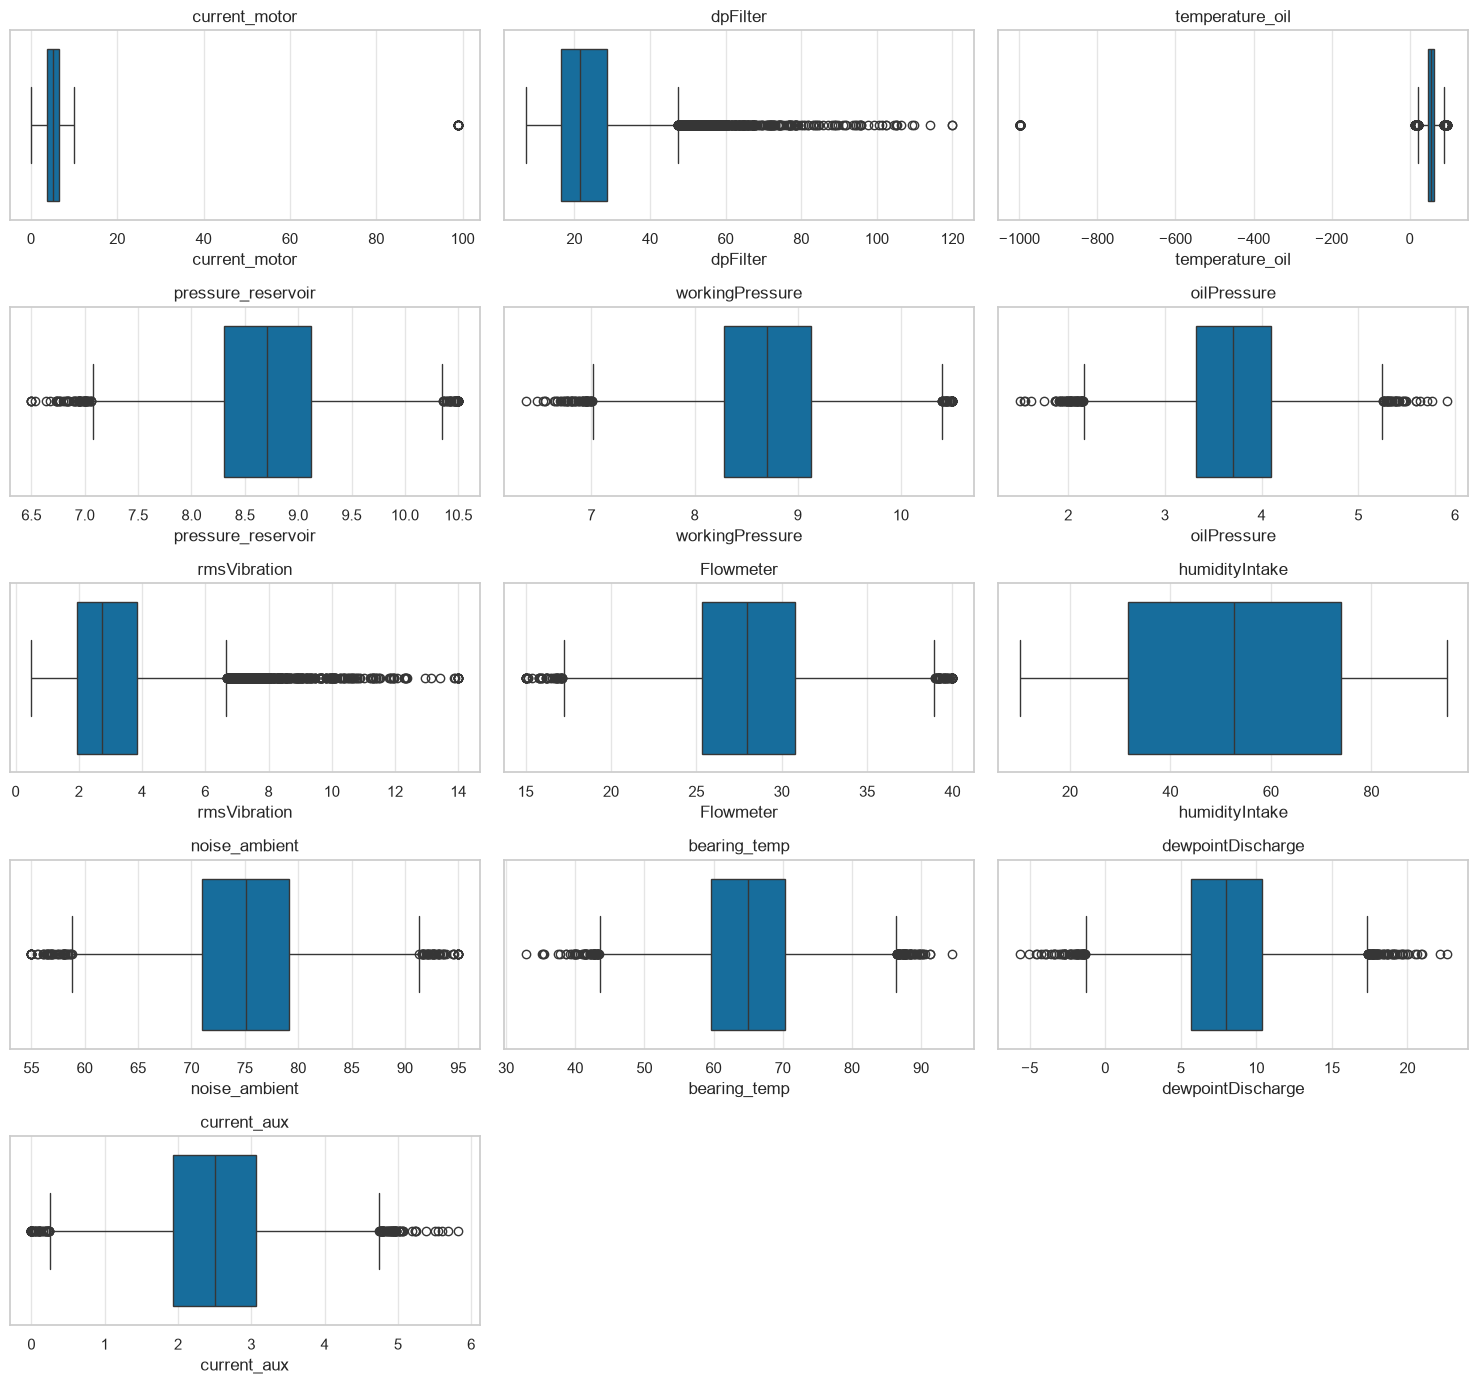

,počet,podiel
Failure,,
0,14148,0.8822
1,1890,0.1178


In [17]:
eda = raw["readings"].copy()
descriptions = {
"current_motor":"prúd motora", "dpFilter":"tlakový rozdiel filtra", "temperature_oil":"teplota oleja",
"pressure_reservoir":"tlak zásobníka", "workingPressure":"pracovný tlak", "oilPressure":"tlak oleja",
"rmsVibration":"RMS vibrácie", "Flowmeter":"prietok", "humidityIntake":"vlhkosť nasávania",
"noise_ambient":"okolitý hluk", "bearing_temp":"teplota ložiska", "dewpointDischarge":"rosný bod výstupu", "current_aux":"pomocný prúd"}
desc = eda[sensors].describe(percentiles=[.05,.25,.5,.75,.95]).T
desc.insert(0,"význam", pd.Series(descriptions))
desc["chýba %"] = eda[sensors].isna().mean()*100
desc["šikmosť"] = eda[sensors].skew()
display(desc)
fig, axes = plt.subplots(5,3,figsize=(15,17))
for c, ax in zip(sensors, axes.flat):
    sns.histplot(eda[c].dropna(), bins=40, ax=ax)
    ax.set_title(c); ax.set_ylabel("Počet")
for ax in axes.flat[len(sensors):]: ax.axis("off")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(5,3,figsize=(15,14))
for c, ax in zip(sensors, axes.flat):
    sns.boxplot(x=eda[c], ax=ax); ax.set_title(c)
for ax in axes.flat[len(sensors):]: ax.axis("off")
plt.tight_layout(); plt.show()
display(eda.groupby("Failure").size().rename("počet").to_frame().assign(podiel=lambda d:d["počet"]/len(eda)))


**Predbežná interpretácia:** histogram teploty oleja odhaľuje −999, ktoré výrazne ovplyvňuje priemer aj mierku grafu; zatiaľ ho ponechávame viditeľné. Prúd motora obsahuje extrém 99. Tlakový rozdiel filtra a vibrácie majú pravý chvost, preto sledujeme medián a kvartily spolu s priemerom.

Tlak zásobníka, pracovný tlak a tlak oleja majú sústredené rozdelenia. Flowmeter je približne symetrický okolo 28. Vlhkosť je v pozorovanom rozsahu približne rovnomerná. Okolitý hluk, teplota ložiska, rosný bod a pomocný prúd majú približne zvonovitý tvar. Záporný rosný bod nie je automaticky chyba. Ide o vizuálny opis, nie potvrdenie normality.

Cieľ je nevyvážený: podiel porúch je približne 11,78 % v surových dátach. Presnú hodnotu po deduplikácii overíme v 1.2. Na základe prvotného auditu zatiaľ neodstraňujeme vysoké senzorové hodnoty, lebo môžu byť signálom poruchy.

## 1.1 C – Vzťahy medzi dvojicami atribútov
Pearsonova korelácia opisuje lineárnu závislosť, Spearmanova monotónnu a je menej citlivá na extrémy. Počítame ich z dostupných dvojíc, bez identifikátorov. Korelácia nepreukazuje príčinu ani nezávislosť.

### Prečo skúmame vzťahy dvoma koreláciami
Porovnanie Pearsonovej a Spearmanovej korelácie pomáha odhaliť, či obraz závislosti výrazne ovplyvňujú extrémy alebo nelineárna monotónna súvislosť. Tepelné mapy majú rovnakú škálu −1 až 1, aby sa dali porovnať. Zoznam najsilnejších dvojíc neobsahuje diagonálu ani zrkadlové opakovania.

Korelácie počítame zo všetkých dostupných párov. Pri rôznych dvojiciach sa môže počet platných pozorovaní líšiť; z týchto korelácií preto nerobíme formálne testy významnosti. Rozptylové grafy používajú najviac 3 000 náhodne vybraných riadkov kvôli prekrytiu bodov; pevné semeno 12 umožňuje rovnaký graf pri opakovanom spustení. Výber na kreslenie nemení dáta použité na výpočet korelácií.

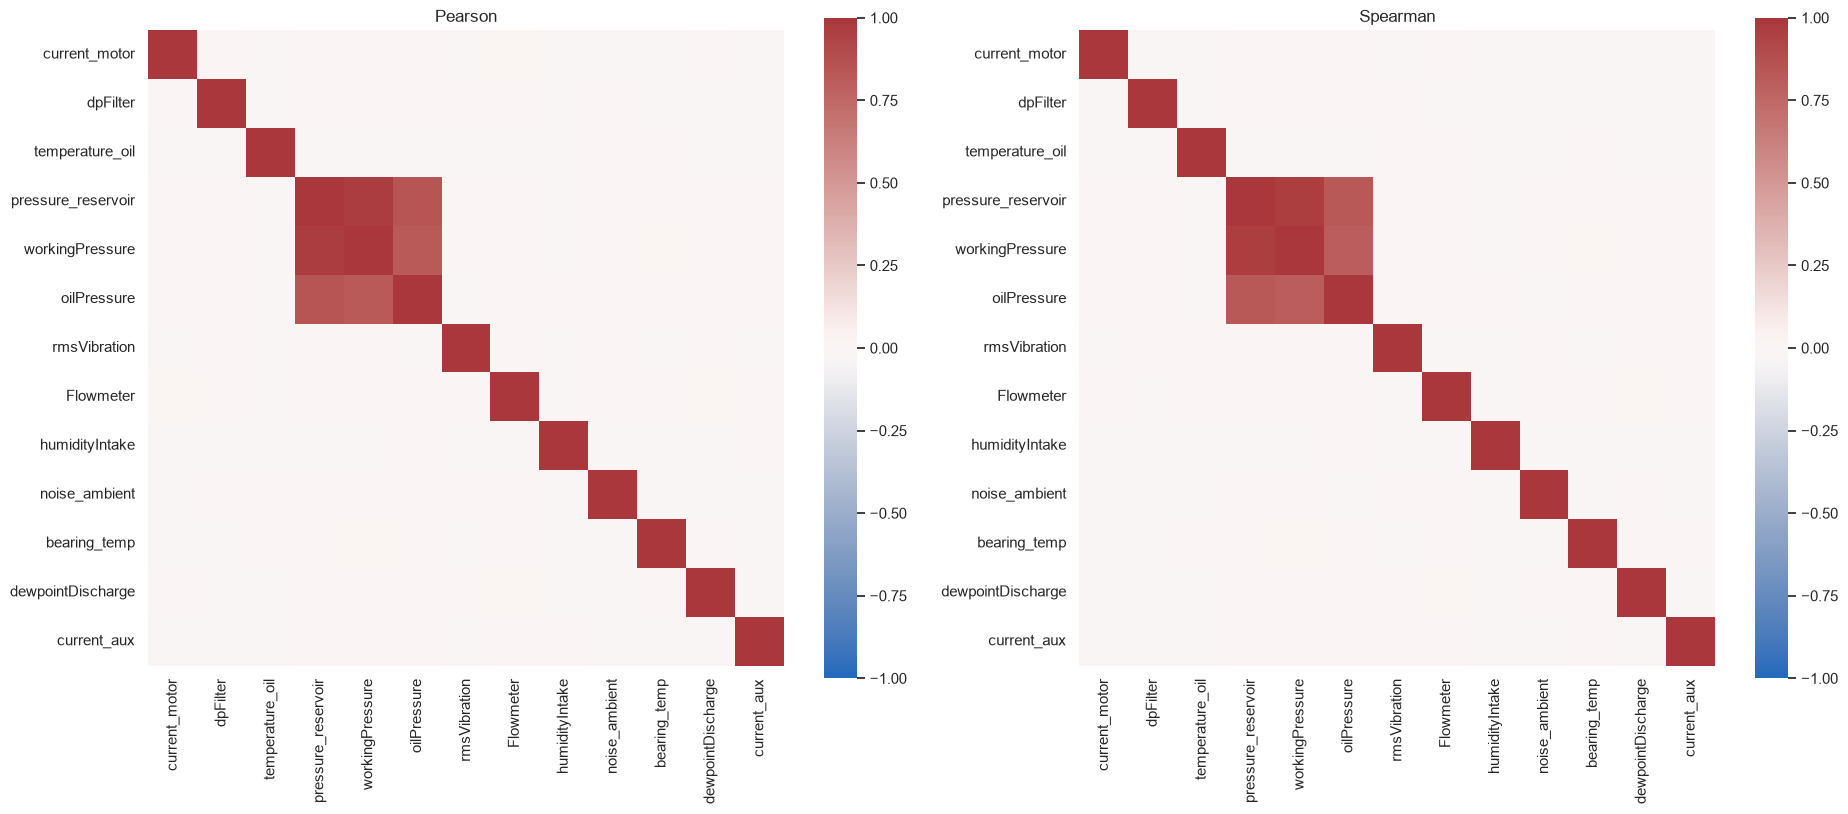

Spearman rho
pressure_reservoir workingPressure          0.9678
                   oilPressure              0.8336
workingPressure    oilPressure              0.8084
current_motor      noise_ambient           -0.0199
Flowmeter          dewpointDischarge        0.0196
rmsVibration       humidityIntake          -0.0181
workingPressure    bearing_temp             0.0158
pressure_reservoir bearing_temp             0.0147
temperature_oil    workingPressure         -0.0145
dpFilter           workingPressure          0.0143

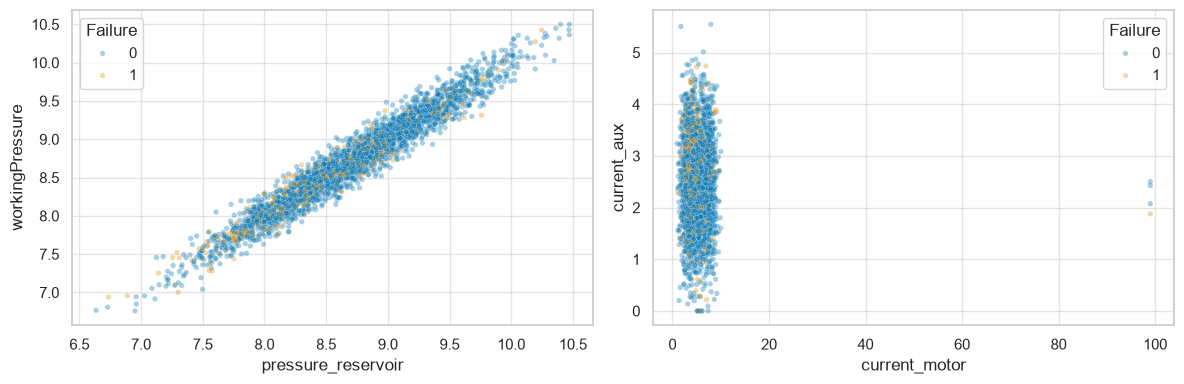

In [18]:
pearson = eda[sensors].corr(method="pearson")
spearman = eda[sensors].corr(method="spearman")
fig, axes = plt.subplots(1,2,figsize=(19,8))
for matrix, title, ax in [(pearson,"Pearson",axes[0]),(spearman,"Spearman",axes[1])]:
    sns.heatmap(matrix, vmin=-1, vmax=1, cmap="vlag", ax=ax, square=True)
    ax.set_title(title)
plt.tight_layout(); plt.show()
pairs = spearman.where(np.triu(np.ones(spearman.shape),1).astype(bool)).stack().rename("Spearman rho").to_frame()
pairs["abs"] = pairs["Spearman rho"].abs()
display(pairs.sort_values("abs", ascending=False).drop(columns="abs").head(10))
fig,axes=plt.subplots(1,2,figsize=(12,4))
sample=eda.sample(min(3000,len(eda)),random_state=12)
sns.scatterplot(data=sample,x="pressure_reservoir",y="workingPressure",hue="Failure",alpha=.35,s=15,ax=axes[0])
sns.scatterplot(data=sample,x="current_motor",y="current_aux",hue="Failure",alpha=.35,s=15,ax=axes[1])
plt.tight_layout(); plt.show()


In [19]:
strongest = pairs.sort_values("abs", ascending=False).head(3)
for (a,b),row in strongest.iterrows():
    display(Markdown(f"**Predbežný vzťah {a} a {b}:** Spearmanovo ρ = {row['Spearman rho']:.3f}. Ide o opis pôvodných meraní; po čistení overíme, či záver ostáva stabilný."))


**Predbežný vzťah pressure_reservoir a workingPressure:** Spearmanovo ρ = 0.968. Ide o opis pôvodných meraní; po čistení overíme, či záver ostáva stabilný.

**Predbežný vzťah pressure_reservoir a oilPressure:** Spearmanovo ρ = 0.834. Ide o opis pôvodných meraní; po čistení overíme, či záver ostáva stabilný.

**Predbežný vzťah workingPressure a oilPressure:** Spearmanovo ρ = 0.808. Ide o opis pôvodných meraní; po čistení overíme, či záver ostáva stabilný.

## 1.1 D – Vzťahy k premennej Failure
V tejto časti používame iba senzory a cieľ, ktoré sú spolu v súbore readings. Metadáta jednotiek a brán porovnáme až po kontrolovanom spojení v 1.2. Vyhneme sa tak skrytému čisteniu alebo spájaniu pred príslušnou časťou zadania.

### Prečo porovnávame skupiny podľa cieľa
Samotná distribúcia senzora neukáže, či súvisí s poruchou. Preto ho porovnáme medzi Failure = 0 a Failure = 1. Priemer môže zachytiť vplyv chvostov, medián rozdiel typických hodnôt a boxplot mieru prekrývania skupín. V týchto skupinových boxplotoch skrývame iba vykreslenie extrémnych bodov pre čitateľnosť; dáta sa neodstraňujú.



Failure                            0         1
current_motor      count  14148.0000 1890.0000
                   mean       5.3139    4.9070
                   median     5.1677    4.5267
dpFilter           count  13874.0000 1555.0000
                   mean      23.5762   27.9655
                   median    20.9988   24.4853
temperature_oil    count  14148.0000 1890.0000
                   mean      51.1161   51.0451
                   median    54.7621   55.2478
pressure_reservoir count  14148.0000 1890.0000
                   mean       8.7296    8.5513
                   median     8.7244    8.5526
workingPressure    count  14148.0000 1890.0000
                   mean       8.7280    8.5474
                   median     8.7267    8.5488
oilPressure        count  14148.0000 1890.0000
                   mean       3.7227    3.5814
                   median     3.7239    3.5840
rmsVibration       count  13835.0000 1526.0000
                   mean       3.0687    3.2711
                   median     2.7169    2.9025
Flowmeter          count  14148.0000 1890.0000
                   mean      28.0424   27.8367
                   median    27.9781   27.9106
humidityIntake     count  13405.0000 1806.0000
                   mean      52.7038   52.7958
                   median    52.6902   51.7879
noise_ambient      count  14148.0000 1890.0000
                   mean      75.0754   75.1645
                   median    75.0801   75.0255
bearing_temp       count  14148.0000 1890.0000
                   mean      64.7743   66.8789
                   median    64.7669   66.8857
dewpointDischarge  count  14148.0000 1890.0000
                   mean       7.9189    8.7071
                   median     7.9225    8.7485
current_aux        count  14148.0000 1890.0000
                   mean       2.4837    2.6396
                   median     2.4828    2.6376

,Pearson s Failure
pressure_reservoir,-0.0956
workingPressure,-0.0938
oilPressure,-0.0801
current_motor,-0.0378
Flowmeter,-0.0166
temperature_oil,-0.0004
humidityIntake,0.0012
noise_ambient,0.0048
rmsVibration,0.0372
current_aux,0.0604


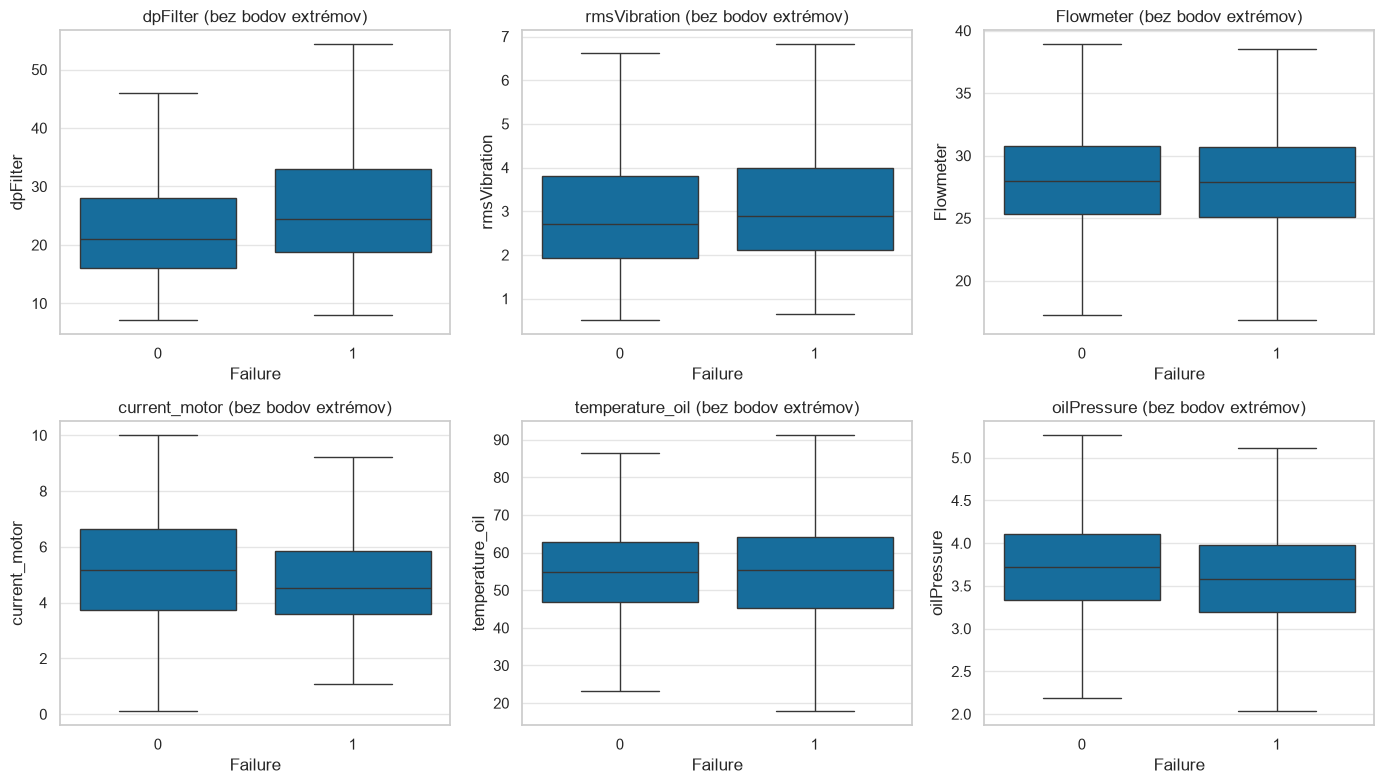

In [20]:
display(eda.groupby("Failure")[sensors].agg(["count","mean","median"]).T)
target_corr = eda[sensors].corrwith(eda.Failure).sort_values()
display(target_corr.rename("Pearson s Failure").to_frame())
fig,axes=plt.subplots(2,3,figsize=(14,8))
for c,ax in zip(["dpFilter","rmsVibration","Flowmeter","current_motor","temperature_oil","oilPressure"],axes.flat):
    sns.boxplot(data=eda,x="Failure",y=c,showfliers=False,ax=ax)
    ax.set_title(c+" (bez bodov extrémov)")
plt.tight_layout(); plt.show()


**Predbežný záver:** skupinové boxploty sa prekrývajú, preto jeden senzor pravdepodobne nebude dokonale oddeľovať stavy. Posun dpFilter a menší posun vibrácie motivujú hypotézy v časti 1.3. Korelácie a priemery tu ešte môžu ovplyvňovať duplicity a sentinel; pred inferenciou preto vykonáme čistenie.

## 1.1 E – Prvotné zamyslenie a plán riešenia
Tlakové senzory sú medzi sebou závislé a môžu poskytovať redundantnú informáciu. Slabá samostatná korelácia ostatných senzorov nevylučuje nelineárny alebo kombinovaný prínos. dpFilter a RMS vibrácie budeme ďalej skúmať ako kandidátov súvisiacich s Failure.

Na preskúmanie vplyvu modelu, záťaže či firmvéru potrebujeme spojiť súbory cez unitId. Pred spojením musíme zjednotiť formáty kľúčov a overiť ich jednoznačnosť. Presné duplicity môžu nadmerne vážiť rovnaké merania; −999 skresľuje teplotné štatistiky. Tieto problémy opravíme, ale nejasné vysoké hodnoty ponecháme na porovnanie dvoch postupov spracovania outlierov.

Opakované merania jedného zariadenia nemusia byť nezávislé. Preto pri hypotézach použijeme rozdiel medzi stavmi v rámci zariadenia. Chronologickú konzistenciu a dostupnosť metadát v čase merania preveríme pred úvahou o budúcej predikcii.

## 1.3 A – Dve hypotézy a štatistické testy
**H1:** v tej istej jednotke je priemerný `dpFilter` pri `Failure = 1` vyšší než pri `Failure = 0`.  
H0: priemerný vnútrojednotkový rozdiel ≤ 0; H1: rozdiel > 0.

**H2:** v tej istej jednotke je priemerná `rmsVibration` pri `Failure = 1` vyššia než pri `Failure = 0`.  
H0: priemerný vnútrojednotkový rozdiel ≤ 0; H1: rozdiel > 0.

Vyšší tlakový rozdiel filtra aj vibrácie sú zmysluplné kandidáty na indikátory problémov, ale samotné dáta nepreukazujú príčinnosť. Hypotézy sú exploračné, formulované v rámci EDA, nie nezávisle predregistrované.

**Jednotka inferencie:** fyzická jednotka APU, nie každý riadok. Opakované merania by pri obyčajnom dvojvýberovom teste vytvárali pseudoreplikáciu. Pre každú známu jednotku vypočítame priemer senzora zvlášť v oboch stavoch a ich rozdiel. Použijeme iba jednotky s oboma stavmi a platnými meraniami. Každá jednotka má rovnakú váhu. Výsledok sa vzťahuje na túto podskupinu, nie na všetky jednotky.

Použijeme jednostranný párový t-test (ekvivalentný jednovýberovému t-testu rozdielov). Vyžaduje nezávislosť jednotiek a dostatočne stabilný výberový priemer; normálnosť jednotlivých meraní nevyžaduje. Ukážeme Q–Q graf rozdielov a citlivosť na odľahlé hodnoty. Predpoklad nezávislosti medzi jednotkami nemožno zo súborov dokázať (spoločné depá môžu vytvárať zhluky).

Rodinná hladina α = 0,05; dva primárne testy korigujeme Holmovou metódou. Uvedieme veľkosť efektu dz, interval pre priemerný rozdiel a párový bootstrap ako kontrolu stability. Konzervatívne 97,5 % obojstranné intervaly dávajú pre dve hypotézy aspoň 95 % súčasné pokrytie pri splnení predpokladov.

### Prečo testujeme rozdiely v rámci jednotiek
Priame porovnanie všetkých riadkov by opakované merania jedného zariadenia počítalo ako nezávislé dôkazy. Agregáciou na dva priemery na jednotku dostaneme jeden rozdiel na zariadenie. Znižujeme tým problém opakovaných meraní a čiastočne zohľadňujeme stabilné rozdiely medzi zariadeniami. Súčasne meníme otázku: odhadujeme priemerný rozdiel medzi stavmi v zariadeniach, ktoré oba stavy majú. Časovo sa meniace podmienky môžu rozdiel stále ovplyvňovať.

Jednostranný test zodpovedá explicitnej hypotéze „vyšší“. Keďže hypotézy vznikli pri EDA, výsledok nemá váhu nezávislého potvrdzujúceho experimentu. Holmova korekcia kontroluje chybu v rodine týchto dvoch testov, nie všetky rozhodnutia urobené počas prieskumu.

Veľkosť efektu dz delí priemerný rozdiel smerodajnou odchýlkou rozdielov; umožňuje posúdiť veľkosť účinku mimo samotnej p-hodnoty. Bootstrap 3 000-krát prevzorkuje celé jednotkové rozdiely, nie jednotlivé merania. Jeho 95 % intervaly sú doplnkové, nekorigované pre viacnásobné porovnávanie. Test zopakujeme aj po oboch outlier postupoch a bez nejednoznačných časových kľúčov, aby sme overili citlivosť záveru na tieto voľby.

,páry,rozdiel,SD rozdielov,dz,t,p,CI97.5 dolná,CI97.5 horná,bootstrap95 dolná,bootstrap95 horná,p Holm,zamietame H0
atribút,,,,,,,,,,,,
dpFilter,984,4.662674,12.648921,0.368622,11.563230,2.187e-29,3.757480,5.567868,3.888893,5.445006,4.375e-29,True
rmsVibration,968,0.215130,1.687491,0.127485,3.966410,3.917e-05,0.093371,0.336889,0.108930,0.322711,3.917e-05,True


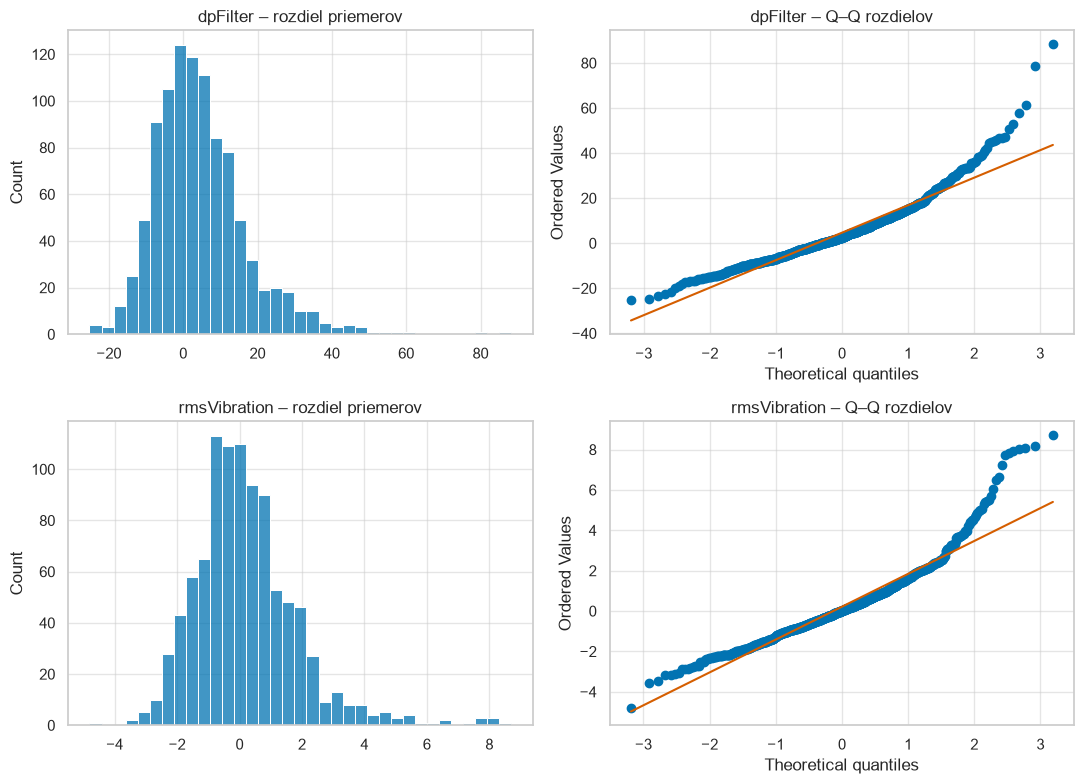

**dpFilter:** 984 párov, priemerný rozdiel 4.663, dz = 0.369, p po Holmovej korekcii = 4.37e-29; H0 **zamietame**. Interval 97,5 %: [3.757; 5.568].

**rmsVibration:** 968 párov, priemerný rozdiel 0.215, dz = 0.127, p po Holmovej korekcii = 3.92e-05; H0 **zamietame**. Interval 97,5 %: [0.093; 0.337].

,variant,atribút,páry,rozdiel,p jednostranné
0,základ po čistení,dpFilter,984,4.6627,0.0000
1,základ po čistení,rmsVibration,968,0.2151,0.0000
2,odstránenie IQR,dpFilter,849,2.6345,0.0000
3,odstránenie IQR,rmsVibration,839,0.1339,0.0012
4,winsorizácia 5–95,dpFilter,984,3.7791,0.0000
5,winsorizácia 5–95,rmsVibration,968,0.1784,0.0000


dpFilter bez nejednoznačných kľúčov: 975 párov; rozdiel 4.6384 p = 1.106e-28
rmsVibration bez nejednoznačných kľúčov: 960 párov; rozdiel 0.2131 p = 4.919e-05


In [21]:
def unit_differences(frame, feature):
    valid=frame.loc[frame.unit_match.eq("both") & frame.Failure.isin([0,1])]
    means=valid.groupby(["unitId","Failure"])[feature].mean().unstack()
    means=means.reindex(columns=[0,1]).dropna()
    return means[1]-means[0]

results=[]; differences={}
rng=np.random.default_rng(12)
for feature in ["dpFilter","rmsVibration"]:
    d=unit_differences(clean,feature);differences[feature]=d
    n=len(d);se=stats.sem(d);t=stats.ttest_1samp(d,0,alternative="greater")
    margin=stats.t.ppf(1-.025/2,n-1)*se
    boot=np.array([rng.choice(d.to_numpy(),size=n,replace=True).mean() for _ in range(3000)])
    results.append({"atribút":feature,"páry":n,"rozdiel":d.mean(),"SD rozdielov":d.std(ddof=1),"dz":d.mean()/d.std(ddof=1),
                    "t":t.statistic,"p":t.pvalue,"CI97.5 dolná":d.mean()-margin,"CI97.5 horná":d.mean()+margin,
                    "bootstrap95 dolná":np.quantile(boot,.025),"bootstrap95 horná":np.quantile(boot,.975)})
tests=pd.DataFrame(results).set_index("atribút")
tests["p Holm"]=multipletests(tests["p"],alpha=.05,method="holm")[1]
tests["zamietame H0"]=tests["p Holm"]<.05
display(tests.style.format({"p":"{:.3e}", "p Holm":"{:.3e}"}))
fig,axes=plt.subplots(2,2,figsize=(11,8))
for row,(feature,d) in enumerate(differences.items()):
    sns.histplot(d,bins=35,ax=axes[row,0]);axes[row,0].set_title(feature+" – rozdiel priemerov")
    stats.probplot(d,dist="norm",plot=axes[row,1]);axes[row,1].set_title(feature+" – Q–Q rozdielov")
plt.tight_layout();plt.show()
for feature,row in tests.iterrows():
    decision="zamietame" if row["zamietame H0"] else "nezamietame"
    display(Markdown(f"**{feature}:** {int(row['páry'])} párov, priemerný rozdiel {row['rozdiel']:.3f}, dz = {row['dz']:.3f}, p po Holmovej korekcii = {row['p Holm']:.3g}; H0 **{decision}**. Interval 97,5 %: [{row['CI97.5 dolná']:.3f}; {row['CI97.5 horná']:.3f}]."))
# Citlivosť: výsledky po oboch outlier postupoch, nie ďalšie primárne hypotézy.
sensitivity=[]
for name,frame in variants.items():
    for feature in differences:
        d=unit_differences(frame,feature)
        sensitivity.append({"variant":name,"atribút":feature,"páry":len(d),"rozdiel":d.mean(),"p jednostranné":stats.ttest_1samp(d,0,alternative="greater").pvalue})
display(pd.DataFrame(sensitivity))

# Citlivosť na nejednoznačný časový kľúč; vynecháme všetky také skupiny.
for feature in differences:
    d=unit_differences(clean.loc[~clean.same_unit_time],feature)
    print(feature, "bez nejednoznačných kľúčov:", len(d), "párov; rozdiel", round(d.mean(),4),
          "p =", format(stats.ttest_1samp(d,0,alternative="greater").pvalue,".3e"))


**Interpretácia testov:** oba rozdiely sú kladné a po Holmovej korekcii štatisticky významné. Efekt dpFilter (dz ≈ 0,369) je väčší než efekt RMS vibrácie (dz ≈ 0,127). Q–Q grafy ukazujú ťažší pravý chvost; veľký počet párov a bootstrap podporujú stabilitu priemeru, no nenahrádzajú predpoklad nezávislosti jednotiek. Aj po IQR filtrácii a winsorizácii zostáva smer rozdielov kladný. Technické prahy praktickej významnosti neboli dodané.

## 1.3 B – Štatistická sila
Namiesto post hoc sily vypočítanej z pozorovaného efektu hodnotíme **citlivosť dizajnu**. Pre párový t-test používame počet nezávislých jednotiek a štandardizovaný rozdiel dz. Pre každú hypotézu nastavíme konzervatívnu hladinu 0,025 (Bonferroni pre dve hypotézy; hlavné výsledky vyššie používajú Holm).

Pracovný cieľ je zachytiť malý efekt **dz = 0,20** so silou aspoň 80 %. Ide o analytickú voľbu, nie o výrobcom určenú praktickú významnosť. Vypočítame silu pre dz = 0,10 / 0,20 / 0,30, požadovaný počet párov a minimálny zachytiteľný efekt pri skutočnom počte párov. Výpočty sú podmienené predpokladmi párového t-testu; neopravujú chyby anotácií ani zhluky medzi jednotkami.

### Prečo nestačí malá p-hodnota
Štatistická sila odpovedá na inú otázku: s akou pravdepodobnosťou by daný dizajn zachytil zvolený skutočný efekt? Nepočítame ju z pozorovaného dz ako dodatočný dôkaz pravdivosti výsledku. Namiesto toho volíme vopred v tejto analýze citlivosti tri scenáre efektu 0,10, 0,20 a 0,30.

Používame počet platných párov, nie počet meraní. Konzervatívne α = 0,025 zohľadňuje dve hypotézy. Cieľ 80 % predstavuje pracovné kritérium dizajnu, nie záruku úspechu jednotlivého testu. Minimálny zachytiteľný efekt pomáha povedať, aké malé rozdiely vie táto vzorka rozlíšiť pri predpokladanej nezávislosti jednotiek.

,páry,sila dz 0.10,sila dz 0.20,sila dz 0.30,páry potrebné pre dz 0.20,min dz pri sile 80%
atribút,,,,,,
dpFilter,984,0.8798,1.0000,1.0000,199,0.0894
rmsVibration,968,0.8746,1.0000,1.0000,199,0.0901


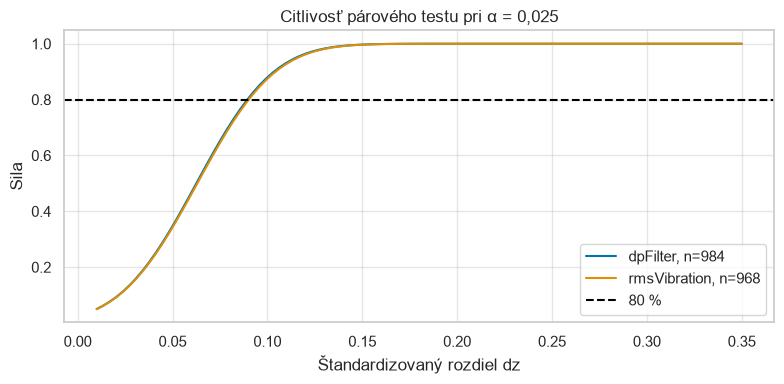

Pre **dpFilter** je sila pre dz = 0,20 **100.0%**. Najmenší efekt zachytiteľný s 80 % silou je dz ≈ **0.089**. Podpora pre zvolený cieľ 80 % je **dostatočná**, ak platia uvedené predpoklady.

Pre **rmsVibration** je sila pre dz = 0,20 **100.0%**. Najmenší efekt zachytiteľný s 80 % silou je dz ≈ **0.090**. Podpora pre zvolený cieľ 80 % je **dostatočná**, ak platia uvedené predpoklady.

In [22]:
power_model=TTestPower(); power_rows=[]
for feature,d in differences.items():
    n=len(d)
    power_rows.append({"atribút":feature,"páry":n,
        "sila dz 0.10":power_model.power(effect_size=.10,nobs=n,alpha=.025,alternative="larger"),
        "sila dz 0.20":power_model.power(effect_size=.20,nobs=n,alpha=.025,alternative="larger"),
        "sila dz 0.30":power_model.power(effect_size=.30,nobs=n,alpha=.025,alternative="larger"),
        "páry potrebné pre dz 0.20":int(np.ceil(power_model.solve_power(effect_size=.20,power=.8,alpha=.025,alternative="larger"))),
        "min dz pri sile 80%":power_model.solve_power(nobs=n,power=.8,alpha=.025,alternative="larger")})
power_table=pd.DataFrame(power_rows).set_index("atribút");display(power_table)
fig,ax=plt.subplots(figsize=(8,4));effects=np.linspace(.01,.35,100)
for feature,d in differences.items():
    ax.plot(effects,power_model.power(effect_size=effects,nobs=len(d),alpha=.025,alternative="larger"),label=f"{feature}, n={len(d)}")
ax.axhline(.8,color="black",ls="--",label="80 %")
ax.set(xlabel="Štandardizovaný rozdiel dz",ylabel="Sila",title="Citlivosť párového testu pri α = 0,025")
ax.legend();plt.tight_layout();plt.show()
for feature,row in power_table.iterrows():
    display(Markdown(f"Pre **{feature}** je sila pre dz = 0,20 **{row['sila dz 0.20']:.1%}**. Najmenší efekt zachytiteľný s 80 % silou je dz ≈ **{row['min dz pri sile 80%']:.3f}**. Podpora pre zvolený cieľ 80 % je **{'dostatočná' if row['sila dz 0.20'] >= .8 else 'nedostatočná'}**, ak platia uvedené predpoklady."))


**Rozhodnutie na základe sily:** pri 984 a 968 platných pároch je sila pre pracovný efekt dz = 0,20 takmer 100 % podľa použitého modelu. Pri dz = 0,10 je približne 88 % a 87 %. Najmenší efekt zachytiteľný s 80 % silou je približne 0,089 a 0,090. Vzorka teda poskytuje dostatočnú podporu pre zvolené malé efekty za predpokladov testu. Pri spoločných vplyvoch depa by skutočný počet nezávislých informácií mohol byť menší; uvedené percentá preto nie sú bezpodmienečnou zárukou.

## Záverečné zhrnutie a rozhodnutia pre ďalšiu fázu
**Hlavné výsledky:** po odstránení 237 presných duplicít ostalo 15 801 meraní; 1 860 má Failure = 1 (11,77 %). Bez metadát je 144 meraní zo 125 neznámych ID. Opravilo sa 52 sentinelových teplôt po deduplikácii. Dve hypotézy podporujú vyšší dpFilter a RMS vibrácie v poruchovom stave v rámci tej istej jednotky.

1. Súbory majú po načítaní správnymi oddeľovačmi použiteľnú tabuľkovú štruktúru. Potrebná je normalizácia kľúčov a dátumov. Spojenie cez `unitId` bolo overené bez zvýšenia počtu meraní.
2. Časť meraní nemá zodpovedajúcu jednotku. Ich senzory možno skúmať, ale ich metadáta nemožno spoľahlivo rekonštruovať. Brány bez priradenia sa do meraní nepridávajú.
3. Presné duplicity a sentinel −999 sú ošetrené. Chýbajúce senzory a prevádzkové hodiny ostávajú explicitne označené. Nejednotná `duty_class` má zdokumentované pracovné mapovanie.
4. Tlak zásobníka a pracovný tlak nesú podobnú informáciu; korelačné výsledky vyššie určujú silu tohto vzťahu. Pre lineárne modely zvážime redundanciu. Slabá marginálna korelácia iného senzora ešte nevylučuje nelineárny alebo podmienený prínos.
5. Testy tlakového rozdielu a vibrácií opisujú rozdiel medzi stavmi v tej istej jednotke. Nejde o dôkaz, že senzor predpovedá **budúcu** poruchu. Cieľový horizont ani predchádzanie senzorov pred udalosťou nie sú definované.
6. Nekonzistentné roky uvedenia a dátumy generálok vyžadujú overenie pôvodu. Bez časovej dostupnosti metadát ich pri predikcii nepoužijeme.
7. V ďalšej fáze najprv vytvoríme časové a/alebo skupinové rozdelenie podľa `unitId` podľa zamýšľaného použitia. Až na tréningu naučíme imputáciu, škálovanie a prípadné hranice outlierov. Identifikátory, MAC, IP a mená technikov nebudú automaticky vstupovať do modelu.
8. Pri nevyváženom cieli budeme porovnávať recall, precision, PR-AUC a maticu zámen s jednoduchým baseline. Odstránenie extrémov musí byť posúdené podľa toho, koľko poruchových stavov stráca.

**Obmedzenia:** chýba dátový slovník s jednotkami a technickými limitmi, niektoré časové pečiatky majú len dennú presnosť a nezávislosť jednotiek nie je zaručená. Hypotézy sú exploračné a následne sa majú overiť na nezávislých dátach. Nezamietnutie H0 by nebolo dôkazom rovnosti.

## Záverečné kontroly
Kontroly zaručujú zachovanie počtu riadkov pri joinoch, platnosť cieľa a úspešné odstránenie identifikovaného sentinelu. Neznamenajú, že všetky zdrojové chyby boli vyriešené.

### Prečo končíme automatickými kontrolami
Podmienky `assert` majú zastaviť notebook, ak sa poruší očakávaný počet riadkov, platnosť cieľa či odstránenie sentinelu. Ide o kontrolu konkrétnych technických vlastností výsledku. Nepreukazujú správnosť anotácií, fyzikálnu platnosť všetkých senzorov ani splnenie predpokladov štatistických testov. Také obmedzenia preto uvádzame aj slovne.

In [23]:
assert len(clean)==len(raw["readings"])-n_duplicates
assert clean.Failure.isin([0,1]).all()
assert not clean.temperature_oil.eq(-999).any()
assert len(sensors)>=10
assert len(winsor)==len(clean)
assert clean.unitId.notna().all() and clean.cycleTs.notna().all()
assert not clean[sensors].isin([np.inf,-np.inf]).any().any()
print("Kontroly prešli. Riadkov:",len(clean),"Senzorov:",len(sensors),"Podiel Failure:",f"{clean.Failure.mean():.2%}")


Kontroly prešli. Riadkov: 15801 Senzorov: 13 Podiel Failure: 11.77%
